# Sensor fidelity — source versus sensors, zero lag versus common sensor delay

**Interactive EDA notebook.** Each section displays its tables and figures inline. The `src/` package performs reusable calculations; **`run_analysis()` is optional and does not create figures**. The lag convention is `source(t)` versus `sensor(t + lag)`. All comparisons use matched timestamps, not row offsets.

In [14]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

# Find config.json by walking upward from Jupyter's current working directory.
# Works when Jupyter starts at /home/ubuntu/notebooks or within Leak_Detection.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "config.json").is_file()), None)
if PROJECT_ROOT is None:
    # Explicit fallback for notebooks launched from /home/ubuntu/notebooks
    candidate = Path.cwd() / "Leak_Detection"
    if (candidate / "config.json").is_file():
        PROJECT_ROOT = candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find project config.json. Set PROJECT_ROOT to your Leak_Detection folder.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.sensor_fidelity.config import load_config
from src.sensor_fidelity.matching import match_recordings
from src.sensor_fidelity.lag_analysis import scan_lags, align_comparison, source_autocorrelation
from src.sensor_fidelity.metrics import all_fidelity_metrics, all_trend_metrics, nonlinear_metrics

SOURCE_OVERRIDE = "source_USB" #None  # None reads config.json; or use "source_USB"
config = load_config(PROJECT_ROOT / "config.json", SOURCE_OVERRIDE)
freqs, sensors = config["freq_cols"], config["sensors"]
lag_cfg = config["lag_analysis"]
min_pairs = lag_cfg["min_pairs"]
print("Project:", PROJECT_ROOT)
print("Selected source:", config["selected_source"])
print("Input directory:", config["data_path"])
print("Output directory:", config["results_path"])


Project: /home/ubuntu/notebooks/Leak_Detection1
Selected source: source_USB
Input directory: /home/ubuntu/notebooks/Leak_Detection1/data/August_Records
Output directory: /home/ubuntu/notebooks/Leak_Detection1/results/source_USB


## 1. Load recordings and match source with sensors at the same timestamps
Only the selected source and three sensors are loaded. Timestamps are parsed and floored to seconds, and duplicate seconds are averaged.

In [15]:
matched, input_summary = match_recordings(config)
display(input_summary)
print("Matched timestamps:", len(matched))
print("Timestamp spacing:")
display(matched["timestamp"].diff().dt.total_seconds().value_counts().rename("count").to_frame().head(10))
display(matched.head(3))

,recording,unique_seconds,first_second,last_second
0,source_USB,179,2026-08-19 15:02:57+00:00,2026-08-19 15:05:55+00:00
1,Thing01,180,2026-08-19 15:02:57+00:00,2026-08-19 15:05:56+00:00
2,Thing02,180,2026-08-19 15:02:57+00:00,2026-08-19 15:05:56+00:00
3,Thing03,180,2026-08-19 15:02:57+00:00,2026-08-19 15:05:56+00:00


Matched timestamps: 179
Timestamp spacing:


,count
timestamp,
1.0,178


,timestamp,f25_source,f31_5_source,f40_source,f50_source,f63_source,f80_source,f100_source,f125_source,f160_source,...,f1250_Thing03,f1600_Thing03,f2000_Thing03,f2500_Thing03,f3100_Thing03,f4000_Thing03,f5000_Thing03,f6300_Thing03,f8000_Thing03,f10000_Thing03
0,2026-08-19 15:02:57+00:00,83.54,69.76,83.37,78.66,85.49,77.52,73.74,72.97,80.44,...,79.85,83.69,86.25,82.26,79.96,76.17,70.74,64.29,69.42,68.88
1,2026-08-19 15:02:58+00:00,81.43,80.09,77.33,79.24,84.18,76.34,72.43,79.56,83.82,...,80.25,80.32,85.31,80.93,82.09,81.26,73.31,65.49,69.18,70.27
2,2026-08-19 15:02:59+00:00,74.50,80.65,77.87,75.66,78.18,78.83,77.57,75.55,85.68,...,84.11,85.41,87.72,86.10,83.03,77.10,72.64,64.26,68.53,67.51


## 2. Search delays 0–30 seconds and estimate one common delay per sensor
At each lag, calculate the 27 per-frequency correlations and maximize their **mean**. The median is displayed as a robustness diagnostic.

In [16]:
lag_results, sensor_lag_curves, best_sensor_lags = scan_lags(
    matched, freqs, sensors,
    lag_cfg["min_lag_seconds"], lag_cfg["max_lag_seconds"], min_pairs
)
delays = dict(zip(best_sensor_lags["sensor"], best_sensor_lags["lag_seconds"].astype(int)))
display(best_sensor_lags.round(3))
print("Selected delays:", delays)

,sensor,lag_seconds,mean_corr,median_corr,frequencies_used,corr_at_zero,improvement
0,Thing01,3,0.534,0.771,27,-0.082,0.617
1,Thing02,3,0.523,0.750,27,-0.091,0.615
2,Thing03,3,0.516,0.718,27,-0.081,0.598


Selected delays: {'Thing01': 3, 'Thing02': 3, 'Thing03': 3}


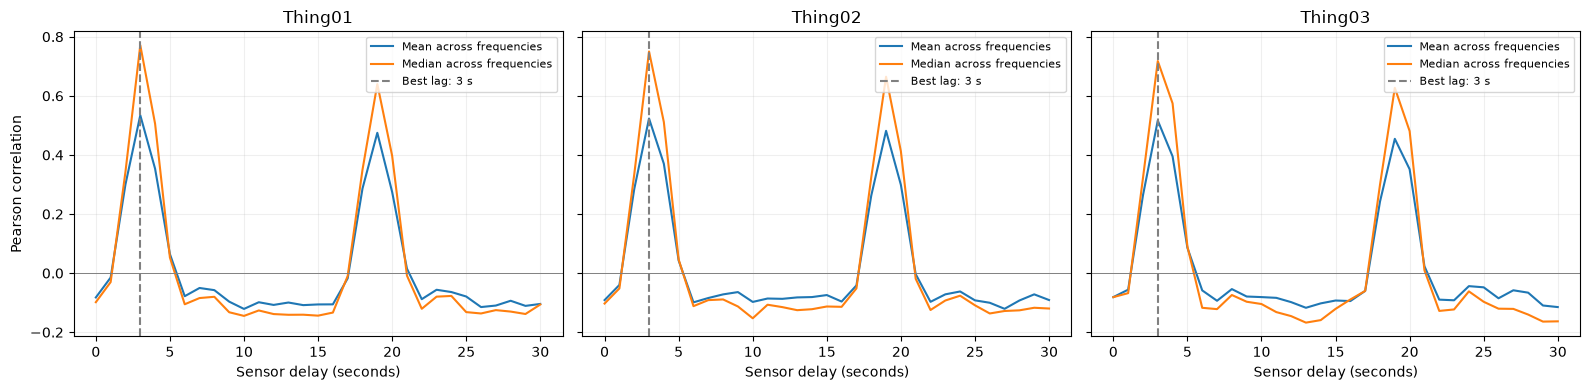

In [17]:
fig, axes = plt.subplots(1, len(sensors), figsize=(16, 4), sharey=True)
for ax, sensor in zip(axes, sensors):
    g = sensor_lag_curves.query("sensor == @sensor")
    ax.plot(g.lag_seconds, g.mean_corr, label="Mean across frequencies")
    ax.plot(g.lag_seconds, g.median_corr, label="Median across frequencies")
    ax.axvline(delays[sensor], ls="--", color="gray", label=f"Best lag: {delays[sensor]} s")
    ax.axhline(0, lw=0.7, color="gray")
    ax.set(title=sensor, xlabel="Sensor delay (seconds)")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Pearson correlation")
plt.tight_layout()
plt.show()

### Diagnostic: how many individual frequencies prefer each lag?
This is **not** the lag selection rule; the common sensor lag is chosen above.

In [18]:
best_per_freq = lag_results.loc[lag_results.groupby(["sensor", "frequency"])["pearson_r"].idxmax()]
lag_counts = best_per_freq.groupby(["sensor", "lag_seconds"]).size().unstack(fill_value=0)
display(lag_counts)

lag_seconds,2,3,5,6,7,11,13,14,17,19,20,21,25,26,27,28,29
sensor,,,,,,,,,,,,,,,,,
Thing01,0,19,1,1,0,0,0,0,1,0,1,1,1,1,0,1,0
Thing02,1,19,0,0,0,0,1,1,1,1,0,0,0,1,0,1,1
Thing03,0,18,1,0,1,1,0,0,0,1,1,0,1,0,1,2,0


## 3. Source autocorrelation — identify periodicity and alias peaks

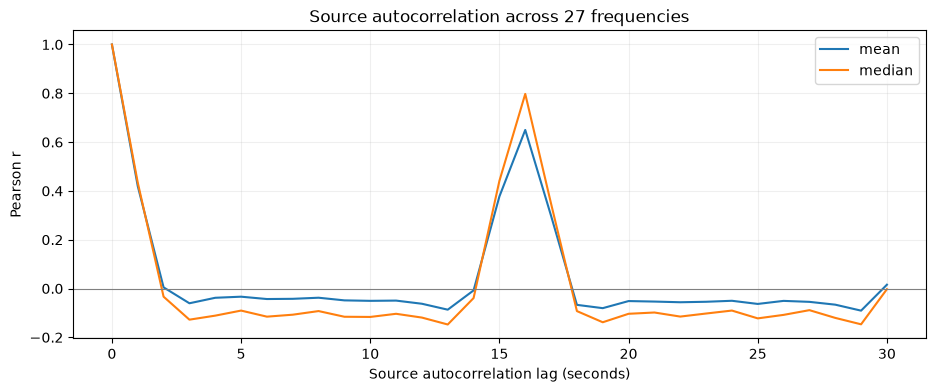

In [19]:
source_acf = source_autocorrelation(matched, freqs, lag_cfg["max_lag_seconds"], min_pairs)
acf_summary = source_acf.groupby("lag_seconds")["autocorr"].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(11, 4))
acf_summary.plot(ax=ax)
ax.axhline(0, color="gray", lw=.8)
ax.set(xlabel="Source autocorrelation lag (seconds)", ylabel="Pearson r", title="Source autocorrelation across 27 frequencies")
ax.grid(alpha=.2)
plt.show()

## 4. Build lag-0 and lag-corrected datasets on the **same source-time window**

In [20]:
zero_df, corrected_df = align_comparison(matched, freqs, sensors, delays, min_pairs)
print("Common timestamps:", len(zero_df))
assert zero_df.timestamp.equals(corrected_df.timestamp)
display(corrected_df.head(3))

Common timestamps: 176


,timestamp,f25_source,f31_5_source,f40_source,f50_source,f63_source,f80_source,f100_source,f125_source,f160_source,...,f1250_Thing03,f1600_Thing03,f2000_Thing03,f2500_Thing03,f3100_Thing03,f4000_Thing03,f5000_Thing03,f6300_Thing03,f8000_Thing03,f10000_Thing03
0,2026-08-19 15:02:57+00:00,83.54,69.76,83.37,78.66,85.49,77.52,73.74,72.97,80.44,...,86.05,85.13,87.02,85.30,80.58,82.07,73.62,65.34,70.35,69.91
1,2026-08-19 15:02:58+00:00,81.43,80.09,77.33,79.24,84.18,76.34,72.43,79.56,83.82,...,86.18,85.50,87.81,82.80,82.77,79.98,72.04,64.36,67.94,69.07
2,2026-08-19 15:02:59+00:00,74.50,80.65,77.87,75.66,78.18,78.83,77.57,75.55,85.68,...,85.13,85.38,86.73,84.17,88.24,79.15,75.79,66.71,68.68,72.34


## 5. Fidelity metrics: zero lag versus best common sensor lag
Includes raw Pearson, first-difference Pearson, regression residual errors, and other original metrics.

In [21]:
all_metrics = all_fidelity_metrics(zero_df, corrected_df, freqs, sensors, delays, min_pairs,
                                   config["eda"].get("amplitude_units", "unknown"))
overall = all_metrics.groupby(["condition", "sensor"], as_index=False).agg(
    mean_pearson_r=("pearson_r", "mean"), median_pearson_r=("pearson_r", "median"),
    mean_diff_r=("diff_r", "mean"), median_residual_nrmse=("residual_nrmse", "median"))
display(overall.round(3))
wide = all_metrics.pivot(index=["frequency", "sensor"], columns="condition", values="pearson_r")
wide["improvement"] = wide["corrected"] - wide["lag_0"]
display(wide.sort_values("improvement", ascending=False).round(3).head(15))

,condition,sensor,mean_pearson_r,median_pearson_r,mean_diff_r,median_residual_nrmse
0,corrected,Thing01,0.534,0.771,0.397,0.636
1,corrected,Thing02,0.523,0.750,0.369,0.661
2,corrected,Thing03,0.516,0.718,0.364,0.696
3,lag_0,Thing01,-0.080,-0.087,-0.055,0.996
4,lag_0,Thing02,-0.085,-0.102,-0.058,0.995
5,lag_0,Thing03,-0.065,-0.078,-0.027,0.996


condition          corrected  lag_0  improvement
frequency sensor                                
f1600     Thing01      0.880 -0.169        1.049
f1000     Thing01      0.858 -0.175        1.033
f1600     Thing02      0.878 -0.146        1.024
f1250     Thing03      0.876 -0.148        1.024
f4000     Thing01      0.875 -0.124        0.999
f1250     Thing02      0.863 -0.136        0.999
          Thing01      0.864 -0.128        0.992
f2000     Thing02      0.858 -0.134        0.991
          Thing03      0.855 -0.132        0.988
f2500     Thing01      0.841 -0.142        0.983
f1000     Thing02      0.824 -0.156        0.980
f1600     Thing03      0.858 -0.121        0.979
f1000     Thing03      0.846 -0.131        0.976
f2500     Thing02      0.874 -0.102        0.976
f2000     Thing01      0.845 -0.128        0.973

## 6. Best-to-worst performing frequencies at the corrected lag
Rank by median Pearson correlation across the three sensors, and show each sensor separately.

In [22]:
corrected_metrics = all_metrics.query('condition == "corrected"')
frequency_quality = corrected_metrics.pivot(index="frequency", columns="sensor", values="pearson_r")[sensors]
frequency_quality["mean_r"] = frequency_quality[sensors].mean(axis=1)
frequency_quality["median_r"] = frequency_quality[sensors].median(axis=1)
frequency_quality = frequency_quality.sort_values("median_r", ascending=False)
print("Best to worst performing frequencies:")
display(frequency_quality.round(3))
print("Worst 10:")
display(frequency_quality.tail(10).round(3))

Best to worst performing frequencies:


sensor,Thing01,Thing02,Thing03,mean_r,median_r
frequency,,,,,
f1600,0.880,0.878,0.858,0.872,0.878
f4000,0.875,0.856,0.867,0.866,0.867
f3100,0.836,0.866,0.868,0.856,0.866
f1250,0.864,0.863,0.876,0.867,0.864
f2500,0.841,0.874,0.860,0.858,0.860
f2000,0.845,0.858,0.855,0.853,0.855
f5000,0.850,0.847,0.836,0.844,0.847
f1000,0.858,0.824,0.846,0.843,0.846
f6300,0.811,0.818,0.809,0.813,0.811


Worst 10:


sensor,Thing01,Thing02,Thing03,mean_r,median_r
frequency,,,,,
f200,0.424,0.314,0.287,0.342,0.314
f160,0.306,0.267,0.157,0.243,0.267
f125,0.214,0.257,0.081,0.184,0.214
f100,0.059,0.087,-0.054,0.030,0.059
f80,-0.015,0.042,0.081,0.036,0.042
f31_5,-0.013,-0.047,0.095,0.011,-0.013
f63,-0.074,-0.029,0.071,-0.011,-0.029
f25,-0.031,-0.091,0.072,-0.017,-0.031
f40,-0.041,-0.061,-0.051,-0.051,-0.051


## 7. Annotated frequency correlation heatmap at corrected lag
Red = positive tracking, blue = negative tracking. Frequency rows are sorted worst to best.

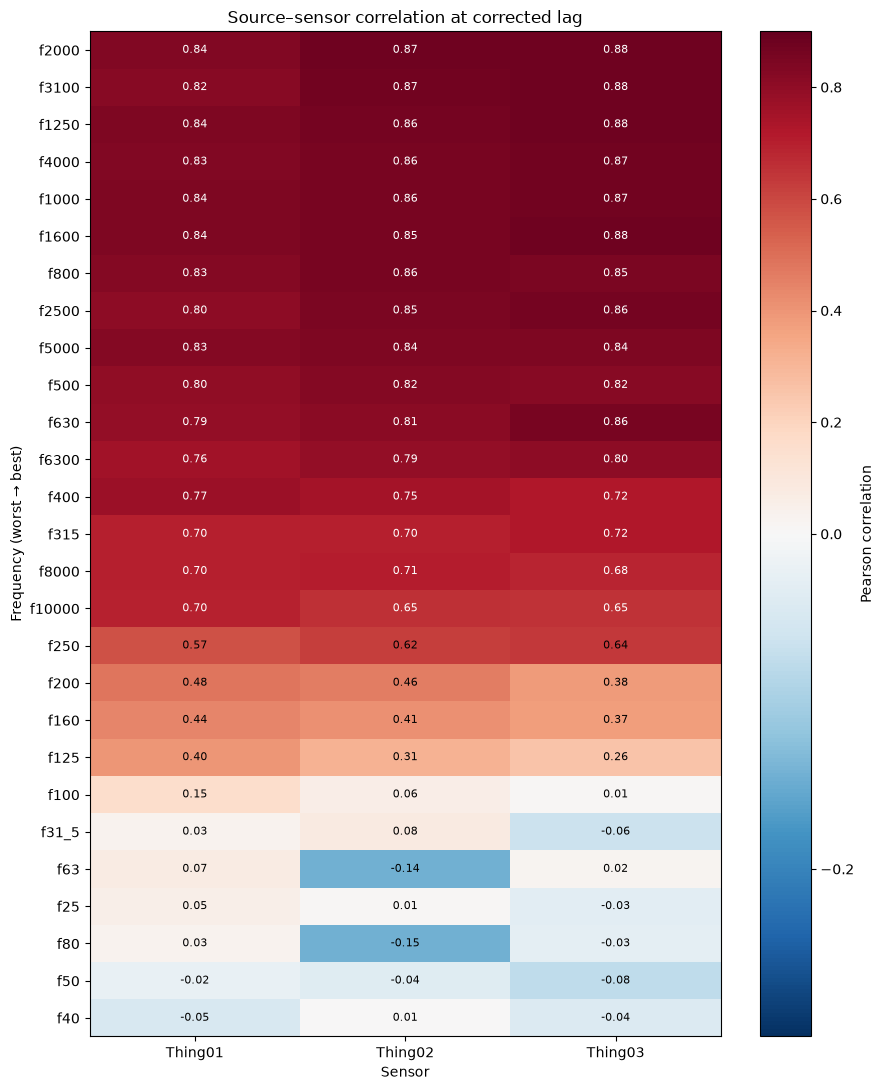

In [13]:
heatmap_df = (
    frequency_quality
    .sort_values("median_r", ascending=False)
    [sensors]
)
fig, ax = plt.subplots(figsize=(9, 11))
# Asymmetric range highlights the strong positive bands while keeping zero white.
norm = TwoSlopeNorm(vmin=-0.3, vcenter=0, vmax=0.9)
im = ax.imshow(heatmap_df.to_numpy(float), cmap="RdBu_r", norm=norm, aspect="auto")
ax.set_xticks(range(len(sensors)), sensors)
ax.set_yticks(range(len(heatmap_df)), heatmap_df.index)
for i in range(len(heatmap_df)):
    for j in range(len(sensors)):
        value = heatmap_df.iloc[i, j]
        if np.isfinite(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if value >= .65 else "black")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set(title="Source–sensor correlation at corrected lag", xlabel="Sensor", ylabel="Frequency (worst → best)")
plt.tight_layout()
plt.show()

## 8. Before/after correlation heatmaps
The same frequencies and sensors are shown at lag 0 and at their common sensor-level lag.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 10), sharey=True)
for ax, condition, title in zip(axes, ["lag_0", "corrected"], ["Lag 0", "Corrected lag"]):
    frame = all_metrics.query("condition == @condition").pivot(index="frequency", columns="sensor", values="pearson_r")
    frame = frame.reindex(index=freqs, columns=sensors)
    im = ax.imshow(frame.to_numpy(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(sensors)), sensors)
    ax.set_yticks(range(len(freqs)), freqs)
    ax.set_title(title)
fig.colorbar(im, ax=axes, label="Pearson correlation", shrink=.65)
plt.show()

## 9. Temporal trend tracking and direction agreement
Calculate smoothed-trend correlation and agreement in rise/fall direction at lag 0 and corrected lag.

In [ ]:
trend_results = all_trend_metrics(zero_df, corrected_df, freqs, sensors,
                                  config["eda"]["smoothing_window"], min_pairs)
trend_summary = trend_results.groupby(["condition", "sensor"])[
    ["trend_corr", "direction_agreement", "smoothed_diff_corr"]].mean()
display(trend_summary.round(3))

## 10. Inspect any frequency and sensor — source versus corrected signal
Standardization removes offset and scale so you can visually assess temporal co-movement. No smoothing is applied.

In [ ]:
FREQUENCY_TO_PLOT = "f2000"
SENSOR_TO_PLOT = "Thing03"

def plot_overlay(freq, sensor, frame, title):
    x = frame[f"{freq}_source"].astype(float)
    y = frame[f"{freq}_{sensor}"].astype(float)
    xz = (x - x.mean()) / x.std() if x.std() > 0 else x * np.nan
    yz = (y - y.mean()) / y.std() if y.std() > 0 else y * np.nan
    r = x.corr(y)
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(frame.timestamp, xz, label="Source", lw=2)
    ax.plot(frame.timestamp, yz, label=sensor, lw=1.5, alpha=.85)
    ax.set(title=f"{title}: {freq} / {sensor} | r={r:.3f}", xlabel="Source timestamp", ylabel="Standardized amplitude")
    ax.grid(alpha=.2); ax.legend()
    plt.tight_layout(); plt.show()

plot_overlay(FREQUENCY_TO_PLOT, SENSOR_TO_PLOT, zero_df, "Lag 0")
plot_overlay(FREQUENCY_TO_PLOT, SENSOR_TO_PLOT, corrected_df,
             f"Corrected lag ({delays[SENSOR_TO_PLOT]} s)")

## 11. Nonlinear dependence diagnostics
Compare Spearman and distance correlation before/after lag correction. These are exploratory, not proof of nonlinear tracking.

In [ ]:
nonlinear_results = nonlinear_metrics(zero_df, corrected_df, freqs, sensors, min_pairs)
display(nonlinear_results.query('condition == "corrected"')
        .sort_values("distance_corr", ascending=False).head(15).round(3))

## 12. Optional: save numerical results to `results/`
**No plots are generated by `run_analysis()`.** This cell saves the numerical outputs produced above; figures are displayed interactively in the notebook.

In [ ]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    out = config["results_path"]
    tables, data_out = out / "tables", out / "data"
    tables.mkdir(parents=True, exist_ok=True)
    data_out.mkdir(parents=True, exist_ok=True)
    input_summary.to_csv(tables / "input_summary.csv", index=False)
    matched.to_csv(data_out / "matched_unshifted.csv", index=False)
    lag_results.to_csv(tables / "lag_scan_per_frequency.csv", index=False)
    sensor_lag_curves.to_csv(tables / "sensor_lag_curves.csv", index=False)
    best_sensor_lags.to_csv(tables / "best_sensor_lags.csv", index=False)
    lag_counts.to_csv(tables / "frequency_lag_counts.csv")
    source_acf.to_csv(tables / "source_autocorrelation.csv", index=False)
    zero_df.to_csv(data_out / "matched_zero_lag_same_window.csv", index=False)
    corrected_df.to_csv(data_out / "matched_sensor_delay_corrected.csv", index=False)
    all_metrics.to_csv(tables / "fidelity_metrics_zero_vs_corrected.csv", index=False)
    overall.to_csv(tables / "overall_zero_vs_corrected.csv", index=False)
    frequency_quality.to_csv(tables / "frequency_tracking_quality_corrected.csv")
    trend_results.to_csv(tables / "temporal_trends_zero_vs_corrected.csv", index=False)
    nonlinear_results.to_csv(tables / "nonlinear_zero_vs_corrected.csv", index=False)
    print("Saved numerical results to", out)